BERTopic Topic Modeling (Codebook 3 of 3)

Loads the preprocessed corpus and cached embeddings produced by the preprocessing notebook, fits a BERTopic model (UMAP + HDBSCAN + a vectorizer for topic-word labels) and saves the topic assignments, topic info, model, and visualisations.

1.1
Project root config


In [ ]:

#Single anchor Path for the whole pipeline. Every other path
# (data/outputs/logs/models) is derived from this so the project
# has one consistent, reproducible directory layout.

from pathlib import Path

_PROJECT_ROOT = Path('/content/creativity_topics_project')

#every run time - the files generated will be saved here but deleted after each runtime, so files need to be dowloaded

In [ ]:
import time
import logging
import logging.handlers
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd

1.2 Paths, Hyperparameters & Config

In [ ]:

@dataclass(frozen=True) #this class is an immutable container of values, once its created the files, it cannot be reassigned, path and files are alsways names the same
class PathsConfig:
    """Every filesystem path used by the pipeline."""
    project_root: Path = _PROJECT_ROOT
    data_dir: Path = _PROJECT_ROOT/ "data"
    outputs_dir: Path = _PROJECT_ROOT/ "outputs"
    logs_dir: Path = _PROJECT_ROOT/ "logs"
    models_dir: Path = _PROJECT_ROOT/ "models"

    raw_corpus_csv: Path = _PROJECT_ROOT/ "data"/ "final_cst_corpus_with_fulltext_final.csv"
    cleaned_corpus_csv: Path = _PROJECT_ROOT/ "outputs" / "corpus_cleaned.csv"
    preprocessed_corpus_csv: Path = _PROJECT_ROOT / "outputs" / "corpus_preprocessed.csv"

    embeddings_path: Path = _PROJECT_ROOT / "models" / "document_embeddings.npy"
    bertopic_model_dir: Path = _PROJECT_ROOT / "models" / "bertopic_model"

    topic_info_csv: Path = _PROJECT_ROOT / "outputs" / "topic_info.csv"
    document_topics_csv: Path = _PROJECT_ROOT / "outputs" / "document_topics.csv"
    evaluation_report_json: Path = _PROJECT_ROOT / "outputs" / "evaluation_report.json"

    log_file: Path = _PROJECT_ROOT / "logs" / "pipeline.log"

    def all_directories(self) -> List[Path]:
        return [self.data_dir, self.outputs_dir, self.logs_dir, self.models_dir]

In [ ]:
@dataclass(frozen=True) #to dont change values

#dimensionality reduction
class UMAPConfig:
    n_neighbors: int = 15
    n_components: int = 5
    min_dist: float = 0.0
    metric: str = "cosine"
    random_state: int = 42

#clusering settings
@dataclass(frozen=True)
class HDBSCANConfig:
    min_cluster_size: int = 5
    #bertopic generic default- MEANING cluster should have at least 4 observations/points to be considered a cluster.
    #IGOOD TO TRY WITH DIFFERENT CLUSTER SIZES AND THEN CHANGE

    min_samples: Optional[int] = None
    metric: str = "euclidean" #tells HDBSCAN to use euclidean distance
    cluster_selection_method: str = "leaf" #excess of mass
    prediction_data: bool = True #makes the model retain information needed for later prediction.

#once doing the BERTopic modeling stage, try something like min_cluster_size = 5, 8, 10, 15
#THEN LOOK AT NUM OF TOPICS PRODUCED, PROP.OF DOC LABELED AS NOISE , CHECK IF THE TOPIC INTEPRETABLE



#n-gram/ document fequency settings
@dataclass(frozen=True)
class VectorizerConfig:
    ngram_range: tuple = (1, 2)
    min_df: int = 2
    max_df: float = 0.95


@dataclass(frozen=True)
class BERTopicConfig: #embedding model, top_n_words etc
    # bge-m3: 1024-dim, 8192-token window (matches the chunked+pooled
    # embeddings uploaded above, not all-mpnet-base-v2/768-dim anymore)
    embedding_model_name:str= "BAAI/bge-m3"
    language: str ="english"
    top_n_words:int= 10
    nr_topics:Optional[Any] = None
    calculate_probabilities:bool = True
    verbose:bool= True


@dataclass(frozen=True)
class SpacyConfig: #spaCy model name + custom stop word list
    model_name: str = "en_core_web_sm"
    allowed_pos_tags: Optional[List[str]] = None
    max_length: int = 2_000_000
    custom_stopwords: List[str] = field(default_factory=lambda: [
        "study", "studies", "paper", "papers", "research", "researcher",
        "researchers", "participant", "participants", "method", "methods",
        "methodology", "result", "results", "analysis", "analyses",
        "author", "authors", "table", "tables", "figure", "figures",
        "et", "al", "article", "articles", "journal", "data", "finding",
        "findings", "section", "chapter", "appendix", "vol", "no", "pp",
        "doi", "issn", "isbn", "abstract", "introduction", "conclusion",
        "discussion", "cite", "citation", "citations",
    ])


@dataclass(frozen=True)
class LoggingConfig: #log formatting
    level: int = logging.INFO
    console_format: str = "%(asctime)s| %(levelname)-8s | %(name)s | %(message)s"
    file_format: str = (
        "%(asctime)s |%(levelname)-8s| %(name)s |"
        "%(filename)s:%(lineno)d | %(message)s"
    )
    max_bytes: int = 5_000_000
    backup_count: int = 5

In [ ]:
@dataclass(frozen=True)
class Config:
    paths: PathsConfig= field(default_factory=PathsConfig)
    umap: UMAPConfig= field(default_factory=UMAPConfig)
    hdbscan: HDBSCANConfig= field(default_factory=HDBSCANConfig)
    vectorizer: VectorizerConfig= field(default_factory=VectorizerConfig)
    bertopic: BERTopicConfig= field(default_factory=BERTopicConfig)
    spacy: SpacyConfig= field(default_factory=SpacyConfig)
    logging_config: LoggingConfig = field(default_factory=LoggingConfig)

    random_seed: int = 42

    required_columns: List[str] = field(default_factory=lambda: [
        "ref_num", "doi", "title", "abstract", "year", "source",
        "fulltext_status", "fulltext",
    ])

    fulltext_column: str= "fulltext"
    clean_text_column: str= "clean_text"
    fulltext_status_column:str = "fulltext_status"
    successful_status_values:List[str]= field(default_factory=lambda: ["PDF_OK"])

    def ensure_directories(self) -> None: #creates all folders if missing
        for directory in self.paths.all_directories():
            directory.mkdir(parents=True, exist_ok=True)

    def configure_logging(self) -> logging.Logger: #sets up a logger that writes to both console and a rotating log file
        self.paths.logs_dir.mkdir(parents=True, exist_ok=True)
        root_logger = logging.getLogger("creativity_topics")
        root_logger.setLevel(self.logging_config.level)

        if root_logger.handlers:
            return root_logger

        console_handler = logging.StreamHandler()
        console_handler.setFormatter(logging.Formatter(self.logging_config.console_format))
        console_handler.setLevel(self.logging_config.level)

        file_handler= logging.handlers.RotatingFileHandler(
            filename=str(self.paths.log_file),
            maxBytes=self.logging_config.max_bytes,
            backupCount=self.logging_config.backup_count,
            encoding="utf-8",
        )
        file_handler.setFormatter(logging.Formatter(self.logging_config.file_format))
        file_handler.setLevel(self.logging_config.level)

        root_logger.addHandler(console_handler)
        root_logger.addHandler(file_handler)
        root_logger.propagate = False
        return root_logger

    def as_dict(self) -> Dict[str, Any]: #placing the key parameters to a plain dict, useful for savign alongside results as a reproducibility recors
        return {
            "random_seed": self.random_seed,
            "embedding_model_name": self.bertopic.embedding_model_name,
            "spacy_model": self.spacy.model_name,
            "umap": {"n_neighbors": self.umap.n_neighbors, "n_components": self.umap.n_components,
                      "min_dist": self.umap.min_dist, "metric": self.umap.metric},
            "hdbscan": {"min_cluster_size": self.hdbscan.min_cluster_size, "min_samples": self.hdbscan.min_samples,
                        "metric": self.hdbscan.metric, "cluster_selection_method": self.hdbscan.cluster_selection_method},
            "bertopic": {"top_n_words": self.bertopic.top_n_words, "nr_topics": self.bertopic.nr_topics,
                         "calculate_probabilities": self.bertopic.calculate_probabilities},
            "raw_corpus_csv": str(self.paths.raw_corpus_csv),
            "cleaned_corpus_csv": str(self.paths.cleaned_corpus_csv),
        }

1.3Instantiate Configuration

In [ ]:
config = Config()
config.ensure_directories()
logger = config.configure_logging()
logger.info("Config loaded successfully")

2026-09-01 11:43:25,286| INFO     | creativity_topics | Config loaded successfully


2.1 UPLOADING PRE PROCESSED CORPUS AND EMBEDDINGS

In [ ]:
from google.colab import files

uploaded = files.upload()  # select corpus_preprocessed.csv and document_embeddings.npy

for filename, content in uploaded.items():
    if filename.endswith(".csv"):
        target = config.paths.preprocessed_corpus_csv
    elif filename.endswith(".npy"):
        target = config.paths.embeddings_path
    else:
        print(f"Skipping unrecognized file: {filename}")
        continue
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)
    print(f"Saved '{filename}' -> {target}")

Saving corpus_preprocessed.csv to corpus_preprocessed.csv
Saving document_embeddings-2.npy to document_embeddings-2.npy
Saved 'corpus_preprocessed.csv' -> /content/creativity_topics_project/outputs/corpus_preprocessed.csv
Saved 'document_embeddings-2.npy' -> /content/creativity_topics_project/models/document_embeddings.npy


2.2 Load data and check


In [ ]:
result_df = pd.read_csv(config.paths.preprocessed_corpus_csv)
embeddings = np.load(config.paths.embeddings_path)

print("result_df shape:", result_df.shape)
print("embeddings shape:", embeddings.shape)
assert len(result_df) == len(embeddings), "Row count mismatch between corpus and embeddings"

result_df shape: (169, 16)
embeddings shape: (169, 1024)


In [ ]:
print(result_df.columns.tolist())
print("embedding_text" in result_df.columns)

['ref_num', 'doi', 'title', 'abstract', 'year', 'source', 'is_oa', 'oa_status', 'oa_url', 'fulltext_status', 'fulltext_source', 'source_url_used', 'failure_reason', 'fulltext', 'clean_text', 'embedding_text']
True


2.3 Document lengths vs embedding modle token limits

In [ ]:
# Word count as a rough proxy for token count  averages
# around 0.75 words per token, like ~1.33 tokens per word

word_counts = result_df['embedding_text'].fillna('').str.split().str.len()
approx_token_counts = (word_counts / 0.75).round().astype(int)

print(" Word counts (embedding_text)")
print(word_counts.describe())
print()
print("Approx. token counts")
print(approx_token_counts.describe())
print()

for limit, label in [(384, "all-mpnet-base-v2"),(512, "bge-base-en-v1.5"),(8192, "bge-m3 /nomic-embed /jina-v2 (current)")]:
    over= (approx_token_counts > limit).sum()
    pct= 100 * over / len(approx_token_counts)
    print(f"Docs exceeding {limit:>5} tokens ({label}): {over}/{len(approx_token_counts)} ({pct:.1f}%)")

# Show the longest few documents by title, so you can see what's driving the tail
longest= result_df.assign(approx_tokens=approx_token_counts).sort_values('approx_tokens', ascending=False)
print("\n--- Longest documents ---")
print(longest[['title', 'approx_tokens']].head(10).to_string(index=False))


 Word counts (embedding_text)
count      169.000000
mean      9136.076923
std       2837.214280
min       1965.000000
25%       7222.000000
50%       8677.000000
75%      10916.000000
max      22230.000000
Name: embedding_text, dtype: float64

Approx. token counts
count      169.000000
mean     12181.443787
std       3782.937982
min       2620.000000
25%       9629.000000
50%      11569.000000
75%      14555.000000
max      29640.000000
Name: embedding_text, dtype: float64

Docs exceeding   384 tokens (all-mpnet-base-v2): 169/169 (100.0%)
Docs exceeding   512 tokens (bge-base-en-v1.5): 169/169 (100.0%)
Docs exceeding  8192 tokens (bge-m3 / nomic-embed / jina-v2 (current)): 149/169 (88.2%)

--- Longest documents ---
                                                                                                                                        title  approx_tokens
                                              Where to Hide a Stolen Elephant: Leaps in Creative Writing with Multimod

3.1 Intalling BERTopic

In [ ]:
!pip install -q bertopic umap-learn hdbscan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 1.8 MB/s eta 0:00:00


3.2 pipeling

In [ ]:
import time
from pathlib import Path
from typing import List, Optional, Tuple

import numpy as np
import pandas as pd


class BERTopicPipelineError(Exception):
    """Used when the BERTopic pipeline cannot be configured, fit, or used."""


class BERTopicPipeline:
    """Configure, train, and persist a BERTopic model for the creativity corpus."""

    def __init__(self, config) -> None:
        self.config = config
        self.logger = logging.getLogger("creativity_topics.bertopic_pipeline")
        self.model = None
        self.topics = None
        self.probabilities = None

    def _build_model(self):
        # This is where UMAP, HDBSCAN, and the vectorizer all get wired
        # together using the hyperparameters already sitting in your Config
        # (config.umap, config.hdbscan, config.vectorizer, config.bertopic).
        try:
            from bertopic import BERTopic
            from umap import UMAP
            from hdbscan import HDBSCAN
            from sklearn.feature_extraction.text import CountVectorizer
        except ImportError as exc:
            message = "Missing dependency. Run: pip install bertopic umap-learn hdbscan scikit-learn"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc

        # UMAP: compresses your embeddings (1024-dim from bge-m3) down to
        # n_components (5 by default) dimensions HDBSCAN can cluster on.
        umap_model = UMAP(
            n_neighbors=self.config.umap.n_neighbors,
            n_components=self.config.umap.n_components,
            min_dist=self.config.umap.min_dist,
            metric=self.config.umap.metric,
            random_state=self.config.random_seed,
            n_jobs=1 # reproducibility
        )

        # HDBSCAN: the actual clustering algorithm — groups similar
        # papers together, and marks genuinely ambiguous ones as
        # "outliers" (topic -1) rather than forcing them into a topic.
        hdbscan_model = HDBSCAN(
            min_cluster_size=self.config.hdbscan.min_cluster_size,
            min_samples=self.config.hdbscan.min_samples,
            metric=self.config.hdbscan.metric,
            cluster_selection_method=self.config.hdbscan.cluster_selection_method,
            prediction_data=self.config.hdbscan.prediction_data,
        )

        # CountVectorizer: decides which WORDS represent each topic —
        # this is where clean_text's heavy cleaning (stopwords/lemmas
        # gone) pays off, producing cleaner topic labels.
        vectorizer_model = CountVectorizer(
            ngram_range=self.config.vectorizer.ngram_range,
            min_df=self.config.vectorizer.min_df,
            max_df=self.config.vectorizer.max_df,
        )

        self.logger.info(
            "Building BERTopic model (umap n_neighbors=%d, n_components=%d; "
            "hdbscan min_cluster_size=%d; vectorizer ngram_range=%s)",
            self.config.umap.n_neighbors, self.config.umap.n_components,
            self.config.hdbscan.min_cluster_size, self.config.vectorizer.ngram_range,
        )

        model = BERTopic(
            umap_model=umap_model,
            hdbscan_model=hdbscan_model,
            vectorizer_model=vectorizer_model,
            top_n_words=self.config.bertopic.top_n_words,
            nr_topics=self.config.bertopic.nr_topics,
            calculate_probabilities=self.config.bertopic.calculate_probabilities,
            verbose=self.config.bertopic.verbose,
        )
        return model

    def fit(self, documents: List[str], embeddings: np.ndarray) -> Tuple[List[int], Optional[np.ndarray]]:
        # documents = clean_text (for topic-word labeling)
        # embeddings = pre-computed vectors from embedding_text (for clustering)
        if len(documents) != embeddings.shape[0]:
            message = f"documents length ({len(documents)}) does not match embeddings row count ({embeddings.shape[0]})"
            self.logger.error(message)
            raise BERTopicPipelineError(message)

        self.model = self._build_model()

        n_documents = len(documents)
        self.logger.info("Fitting BERTopic on %d documents", n_documents)
        start_time = time.perf_counter()
        try:
            topics, probabilities = self.model.fit_transform(documents, embeddings)
        except Exception as exc:
            message = f"BERTopic fitting failed: {exc}"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc
        elapsed = time.perf_counter() - start_time

        self.topics = topics
        self.probabilities = probabilities

        n_topics = len(set(topics)) - (1 if -1 in topics else 0)
        n_outliers = sum(1 for t in topics if t == -1)
        self.logger.info(
            "Fitted BERTopic in %.2f seconds: %d topics found, %d/%d documents classified as outliers (topic -1)",
            elapsed, n_topics, n_outliers, n_documents,
        )

        return topics, probabilities

    def transform(self, documents: List[str], embeddings: np.ndarray):
        self._ensure_fitted()
        self.logger.info("Transforming %d new documents", len(documents))
        try:
            topics, probabilities = self.model.transform(documents, embeddings)
        except Exception as exc:
            message = f"BERTopic transform failed: {exc}"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc
        return topics, probabilities

    def save_model(self, output_dir=None) -> Path:
        self._ensure_fitted()
        path = output_dir or self.config.paths.bertopic_model_dir
        start_time = time.perf_counter()
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            self.model.save(str(path), serialization="safetensors", save_ctfidf=True)
        except Exception as exc:
            message = f"Failed to save BERTopic model to '{path}': {exc}"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc
        elapsed = time.perf_counter() - start_time
        self.logger.info("Saved BERTopic model to '%s' in %.2f seconds", path, elapsed)
        return path

    def load_model(self, input_dir=None) -> "BERTopicPipeline":
        try:
            from bertopic import BERTopic
        except ImportError as exc:
            message = "bertopic is not installed. Run: pip install bertopic"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc

        path = input_dir or self.config.paths.bertopic_model_dir
        if not path.exists():
            message = f"No saved BERTopic model found at '{path}'"
            self.logger.error(message)
            raise BERTopicPipelineError(message)

        start_time = time.perf_counter()
        try:
            self.model = BERTopic.load(str(path))
        except Exception as exc:
            message = f"Failed to load BERTopic model from '{path}': {exc}"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc
        elapsed = time.perf_counter() - start_time
        self.logger.info("Loaded BERTopic model from '%s' in %.2f seconds", path, elapsed)
        return self

    def save_topic_info(self, output_path=None) -> pd.DataFrame:
        self._ensure_fitted()
        path = output_path or self.config.paths.topic_info_csv
        topic_info = self.model.get_topic_info()
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            topic_info.to_csv(path, index=False)
        except OSError as exc:
            message = f"Failed to save topic info to '{path}': {exc}"
            self.logger.error(message)
            raise BERTopicPipelineError(message) from exc
        self.logger.info("Saved topic info (%d topics) to '%s'", len(topic_info), path)
        return topic_info

    def visualize_topics(self):
        self._ensure_fitted()
        self.logger.info("Generating topic visualisation (inter-topic distance map)")
        return self.model.visualize_topics()

    def visualize_hierarchy(self):
        self._ensure_fitted()
        self.logger.info("Generating topic hierarchy visualisation")
        return self.model.visualize_hierarchy()

    def visualize_documents(self, documents: List[str], embeddings: Optional[np.ndarray] = None):
        self._ensure_fitted()
        self.logger.info("Generating document-level visualisation for %d documents", len(documents))
        return self.model.visualize_documents(documents, embeddings=embeddings)

    def _ensure_fitted(self) -> None:
        if self.model is None:
            message = "BERTopicPipeline.fit() or load_model() must be called successfully before this method can be used."
            self.logger.error(message)
            raise BERTopicPipelineError(message)

3.3 FIT the model


In [ ]:
pipeline = BERTopicPipeline(config)

documents = result_df['clean_text'].fillna('').tolist()   # for topic-word labeling
# `embeddings` should already be in memory from the upload step above
# (169, 1024), real semantic vectors from bge-m3, mean-pooled across chunks

topics, probabilities = pipeline.fit(documents, embeddings)

# quick sanity check
print("Number of topics found:", len(set(topics)) - (1 if -1 in topics else 0))
print("Outliers (topic -1):", sum(1 for t in topics if t == -1), "/", len(topics))

2026-09-01 11:50:23,685| INFO     | creativity_topics.bertopic_pipeline | Building BERTopic model (umap n_neighbors=15, n_components=5; hdbscan min_cluster_size=5; vectorizer ngram_range=(1, 2))
2026-09-01 11:50:23,686| INFO     | creativity_topics.bertopic_pipeline | Fitting BERTopic on 169 documents
2026-09-01 11:50:23,692 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-09-01 11:50:37,139 - BERTopic - Dimensionality - Completed ✓
2026-09-01 11:50:37,140 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-09-01 11:50:37,157 - BERTopic - Cluster - Completed ✓
2026-09-01 11:50:37,161 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-09-01 11:50:39,266 - BERTopic - Representation - Completed ✓
2026-09-01 11:50:40,716| INFO     | creativity_topics.bertopic_pipeline | Fitted BERTopic in 17.03 seconds: 8 topics found, 52/169 documents classified as outliers (topic -1)


Number of topics found: 8
Outliers (topic -1): 52 / 169


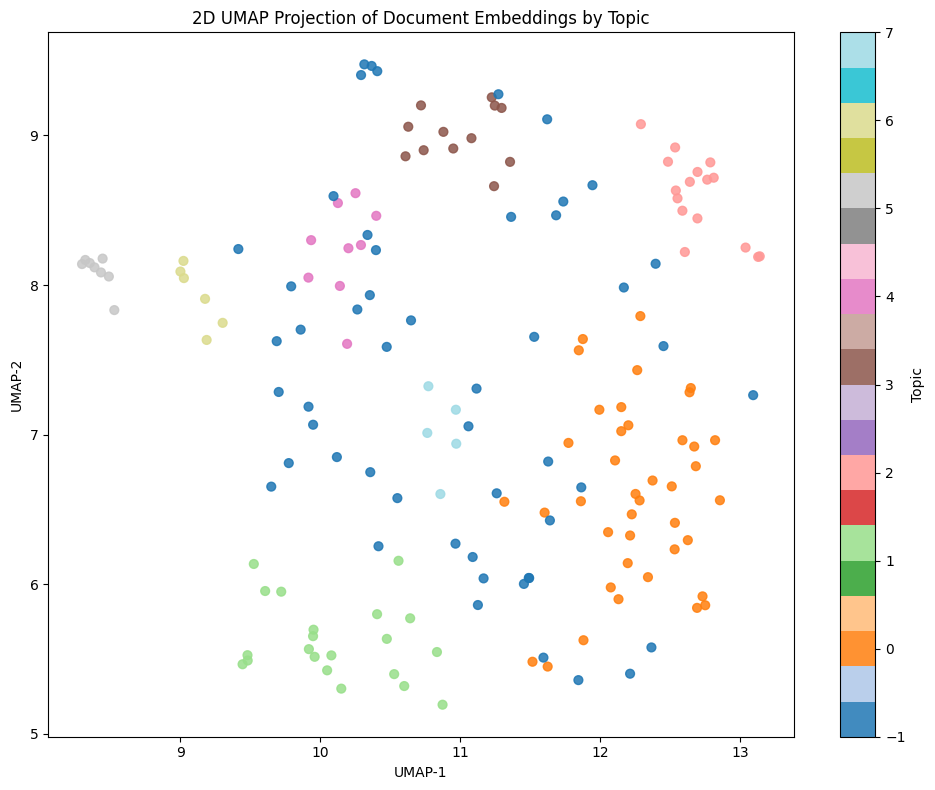

In [ ]:

#SEPARATE UMAP REDUCTION FOR PLOTTING ONLY TO VISUALISE IT

# The UMAP inside pipeline.fit() reduces to 5 dimensions for
# Here the original embedding of 1024 dim is reduced to 2 dimensions to visualise
#how it is spread ou on a graph (on diss document)


import matplotlib.pyplot as plt
from umap import UMAP

umap_2d = UMAP(
    n_neighbors=config.umap.n_neighbors,
    n_components=2,
    min_dist=config.umap.min_dist,
    metric=config.umap.metric,
    random_state=config.umap.random_state,
)
embedding_2d = umap_2d.fit_transform(embeddings)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    c=topics,
    cmap="tab20",
    s=40,
    alpha=0.85,
)
plt.colorbar(scatter, label="Topic")
plt.title("2D UMAP Projection of Document Embeddings by Topic")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.tight_layout()

# Save alongside your other outputs
plt.savefig(config.paths.outputs_dir / "umap_2d_topics.png", dpi=150)
plt.show()

4.2 per paper topic

In [ ]:
# Built a per paper topic assignment table with actual titles
paper_topics = pd.DataFrame({
    "ref_num": result_df["ref_num"],
    "title": result_df["title"],
    "year": result_df["year"],
    "topic": topics,
})
if probabilities is not None:
    paper_topics["probability"] = probabilities.max(axis=1) if probabilities.ndim > 1 else probabilities

paper_topics.to_csv(config.paths.document_topics_csv, index=False)
print("Saved per-paper topic assignments to", config.paths.document_topics_csv)
paper_topics.head(10)

Saved per-paper topic assignments to /content/creativity_topics_project/outputs/document_topics.csv


,ref_num,title,year,topic,probability
0,1,Structuring Online Dyads,2019,2,0.474801
1,2,Escape!Bot: Social Robots as Creative Problem-...,2022,5,1.000000
2,3,Can Children Learn Creativity from a Social Ro...,2019,5,1.000000
3,4,Can Children Emulate a Robotic Non-Player Char...,2020,5,1.000000
4,5,Creativity Encounters Between Children and Robots,2020,5,0.687335
5,7,Homogenization Effects of Large Language Model...,2024,-1,0.111659
6,8,Crowdboard,2017,2,0.430294
7,9,Spellburst: A Node-based Interface for Explora...,2023,-1,0.157123
8,10,ID.8: Co-Creating Visual Stories with Generati...,2024,4,0.302837
9,11,Introducing AV-Sketch: An Immersive Participat...,2024,1,0.303971


4.3 Save topic infor and model

In [ ]:
topic_info = pipeline.save_topic_info()
pipeline.save_model()

topic_info.head(15)

2026-09-01 11:50:41,747| INFO     | creativity_topics.bertopic_pipeline | Saved topic info (9 topics) to '/content/creativity_topics_project/outputs/topic_info.csv'
2026-09-01 11:50:41,836| INFO     | creativity_topics.bertopic_pipeline | Saved BERTopic model to '/content/creativity_topics_project/models/bertopic_model' in 0.09 seconds


,Topic,Count,Name,Representation,Representative_Docs
0,-1,52,-1_llm_edit_template_ml,"[llm, edit, template, ml, viewer, animation, p...",[structured generation exploration design spac...
1,0,40,0_card_analogy_mood board_mood,"[card, analogy, mood board, mood, design space...",[autospark support automobile appearance desig...
2,1,21,1_vr_musical_visualization_adaptive,"[vr, musical, visualization, adaptive, spatial...",[blow mind explore effect scene switching visu...
3,2,16,2_crowd_ideator_worker_generate idea,"[crowd, ideator, worker, generate idea, chat, ...",[crowdboard augment person idea generation rea...
4,3,12,3_writer_journalist_story_variation,"[writer, journalist, story, variation, llm, in...",[metaphorian leverage large language model sup...
5,4,9,4_story_chart_writer_narrative,"[story, chart, writer, narrative, dramatron, c...",[co write screenplay theatre script language m...
6,5,8,5_robot_child_social robot_drawing,"[robot, child, social robot, drawing, non crea...",[creativebot creative storyteller robot stimul...
7,6,6,6_child_story_scratch_storytelling,"[child, story, scratch, storytelling, collage,...",[chatscratch ai augmented system autonomous vi...
8,7,5,7_co creative_human ai_creative system_drawing,"[co creative, human ai, creative system, drawi...",[draw reframer emergence control co creative a...


4.4 Inspect papaers by topic

In [ ]:
for topic_num in sorted(paper_topics['topic'].unique()):
    subset = paper_topics[paper_topics['topic'] == topic_num]
    label = "OUTLIERS" if topic_num == -1 else f"Topic {topic_num}"
    print(f"\n=== {label} ({len(subset)} papers) ===")
    for _, row in subset.iterrows():
        print(f"  - {row['title']} ({row['year']})")


=== OUTLIERS (52 papers) ===
  - Homogenization Effects of Large Language Models on Human Creative Ideation (2024)
  - Spellburst: A Node-based Interface for Exploratory Creative Coding with Natural Language Prompts (2023)
  - Paper2Wire (2020)
  - EditScribe: Non-Visual Image Editing with Natural Language Verification Loops (2024)
  - GRIDS: Interactive Layout Design with Integer Programming (2020)
  - Creativity in Authentic STEAM Education with EarSketch (2017)
  - Cine-AI: Generating Video Game Cutscenes in the Style of Human Directors (2022)
  - ContextCam: Bridging Context Awareness with Creative Human-AI Image Co-Creation (2024)
  - Painting an Apple with an Apple (2018)
  - What Shall I Write Next? (2017)
  - Creative and Progressive Interior Color Design with Eye-tracked User Preference (2022)
  - An Interactive System for Supporting Creative Exploration of Cinematic Composition Designs (2024)
  - CoColor: Interactive Exploration of Color Designs (2023)
  - Supermind Ideator:

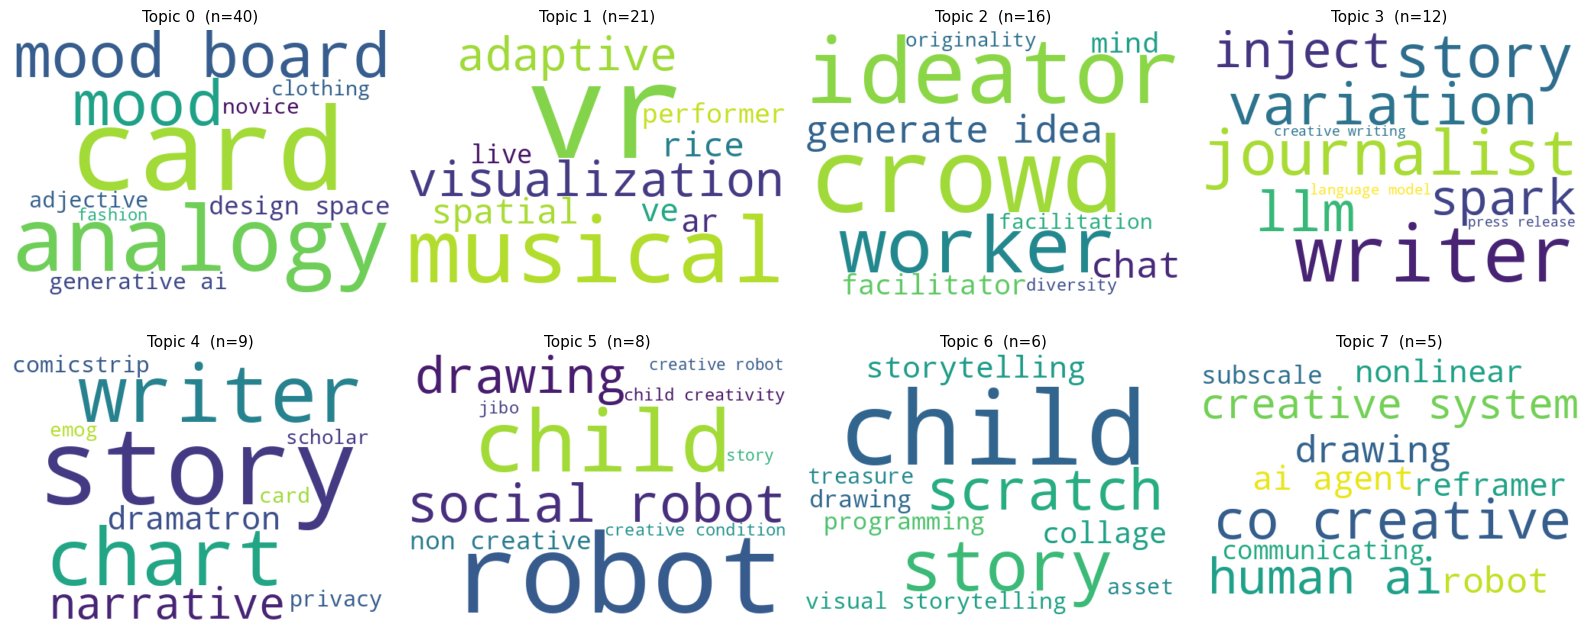

In [ ]:
# Install if not already available
!pip install -q wordcloud

from wordcloud import WordCloud
import matplotlib.pyplot as plt
import math


def plot_topic_wordclouds(pipeline, topics_list=None, exclude_outliers=True, max_words=30, cols=4):
    """
    Grid of word clouds, one per topic, sized by each word's c-TF-IDF score.
    """
    model= pipeline.model
    if model is None:
        raise ValueError("pipeline.model is not fitted yet -- run pipeline.fit(...) first.")

    if topics_list is None:
        topics_list = sorted(set(pipeline.topics))
        if exclude_outliers and -1 in topics_list:
            topics_list.remove(-1)

    rows= math.ceil(len(topics_list) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
    axes= axes.flatten() if len(topics_list) > 1 else [axes]

    for ax, topic_num in zip(axes, topics_list):
        word_scores = dict(model.get_topic(topic_num))  # {word: c-TF-IDF score}
        if not word_scores:
            ax.axis("off")
            continue

        wc = WordCloud(
            width=500,
            height=350,
            background_color="white",
            max_words=max_words,
            colormap="viridis",
            prefer_horizontal=1.0,
        ).generate_from_frequencies(word_scores)

        ax.imshow(wc, interpolation="bilinear")
        n_papers = sum(1 for t in pipeline.topics if t == topic_num)
        ax.set_title(f"Topic {topic_num}(n={n_papers})", fontsize=11)
        ax.axis("off")


    for ax in axes[len(topics_list):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(config.paths.outputs_dir / "topic_wordclouds.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_topic_wordclouds(pipeline, cols=4)